In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from tqdm import tqdm
import sys
import os
import mdtraj as md

sys.path.append('..')
from src import visualisation as vis

In [ ]:
from src.claude.analysis.blocking import BlockAnalysis

@np.vectorize
def calc_Kd(fraction_bound, concentration):
    fc = fraction_bound
    Pt = concentration
    Lt = Pt
    if fc <= 0.0: return 0
    if fc >= 1.0: return np.inf
    Kd = Pt * fc + Lt / fc - Pt - Lt
    return Kd

def calc_fc_sem_blocking(bound_frames):

    # Block analysis estimates for Fc and its SEM
    ba = BlockAnalysis(bound_frames)
    ba.SEM()
    print(f"Using block size of {ba.bs:.0f} frames...")
    Fc, Fc_sem = ba.av, ba.sem

    return Fc_sem

def calc_Kd_blocking(bound_frames, chain_concentration, n_sem:float = 1):

    # Block analysis estimates for Fc and its SEM
    ba = BlockAnalysis(bound_frames)
    ba.SEM()
    print(f"Using block size of {ba.bs:.0f} frames...")
    Fc, Fc_sem = ba.av, ba.sem

    # Calculate Kd and its ± 1 SEM interval
    Kd = calc_Kd(Fc, chain_concentration)
    Kd_lower = calc_Kd(Fc + n_sem*Fc_sem, chain_concentration)
    Kd_upper = calc_Kd(Fc - n_sem*Fc_sem, chain_concentration)

    return (Kd_lower, Kd, Kd_upper)

## PRM-SH3 Single-chain single-repeat Test Run

In [ ]:
# Loading trajectory
pdb_path = "/home/fknudsen/calvados-slim/data/test/slabC3_COM_LJcutoff2.0Gocutoff2.0_GoTrueGo_basic_2.45epsilon_GopairsCutoff0.95_box707070_1/PRM1_SH31_1_1/traj_centered.pdb"
dcd_path = "/home/fknudsen/calvados-slim/data/test/slabC3_COM_LJcutoff2.0Gocutoff2.0_GoTrueGo_basic_2.45epsilon_GopairsCutoff0.95_box707070_1/PRM1_SH31_1_1/traj_centered.dcd"

traj = md.load(dcd_path, top=pdb_path)
n_frames = len(traj)
total_time = (n_frames//4000) * 45000 # ns
dt = total_time/n_frames
time = np.arange(0,total_time, step=dt)

In [ ]:
# Specifying chains
prm_indices = traj.topology.select('chainid 0')
sh3_indices = traj.topology.select('chainid 1')

# Specifying pairs
pair_indices = np.array(np.meshgrid(prm_indices, sh3_indices)).T.reshape(-1, 2)

# Loading SLiM GO pairs
slim_pair_indices = np.load('../data/test/slabC3_COM_LJcutoff2.0Gocutoff2.0_GoTrueGo_basic_2.45epsilon_GopairsCutoff0.95_box707070_1/PRM1_SH31_1_1/0/Go_pairs_list.npy')

In [ ]:
# Calculating concentration
box_volume = traj.unitcell_volumes[0] * 1e-24 # L
N_A = 6.02e23
chains = 1
chain_concentration = 1e6 * (chains) / (N_A * box_volume) # µM

In [ ]:
# Minimum distance
pair_dists = md.compute_distances(traj, pair_indices, periodic=True) * 10.0 # Å
min_dists = pair_dists.min(axis=1)

# COG distance
cogs_prm = np.mean(traj.xyz[:, prm_indices, :], axis=1) * 10.0 # Å
cogs_sh3 = np.mean(traj.xyz[:, sh3_indices, :], axis=1) * 10.0 # Å
cog_dists = np.linalg.norm(cogs_prm - cogs_sh3, axis=1)

# SLiM contacts
contact_cutoff = 9.5 # Å
bound_cutoff = 0.05 # Fraction of contacts
slim_dists = md.compute_distances(traj, slim_pair_indices, periodic=True) * 10.0 # Å
slim_contacts = slim_dists <= contact_cutoff
bound_frames = slim_contacts.mean(axis=1) > bound_cutoff
transitions = bound_frames[:-1] != bound_frames[1:]
fraction_bound = bound_frames.mean()
Kd_lower, Kd, Kd_upper = calc_Kd_blocking(bound_frames.astype(int), chain_concentration)
print(f"{Kd=:.2f}µM ({Kd_lower:.2f}µM ; {Kd_upper:.2f}µM)")

Using block size of 5 frames...
Kd=307.96µM (281.75µM ; 339.35µM)


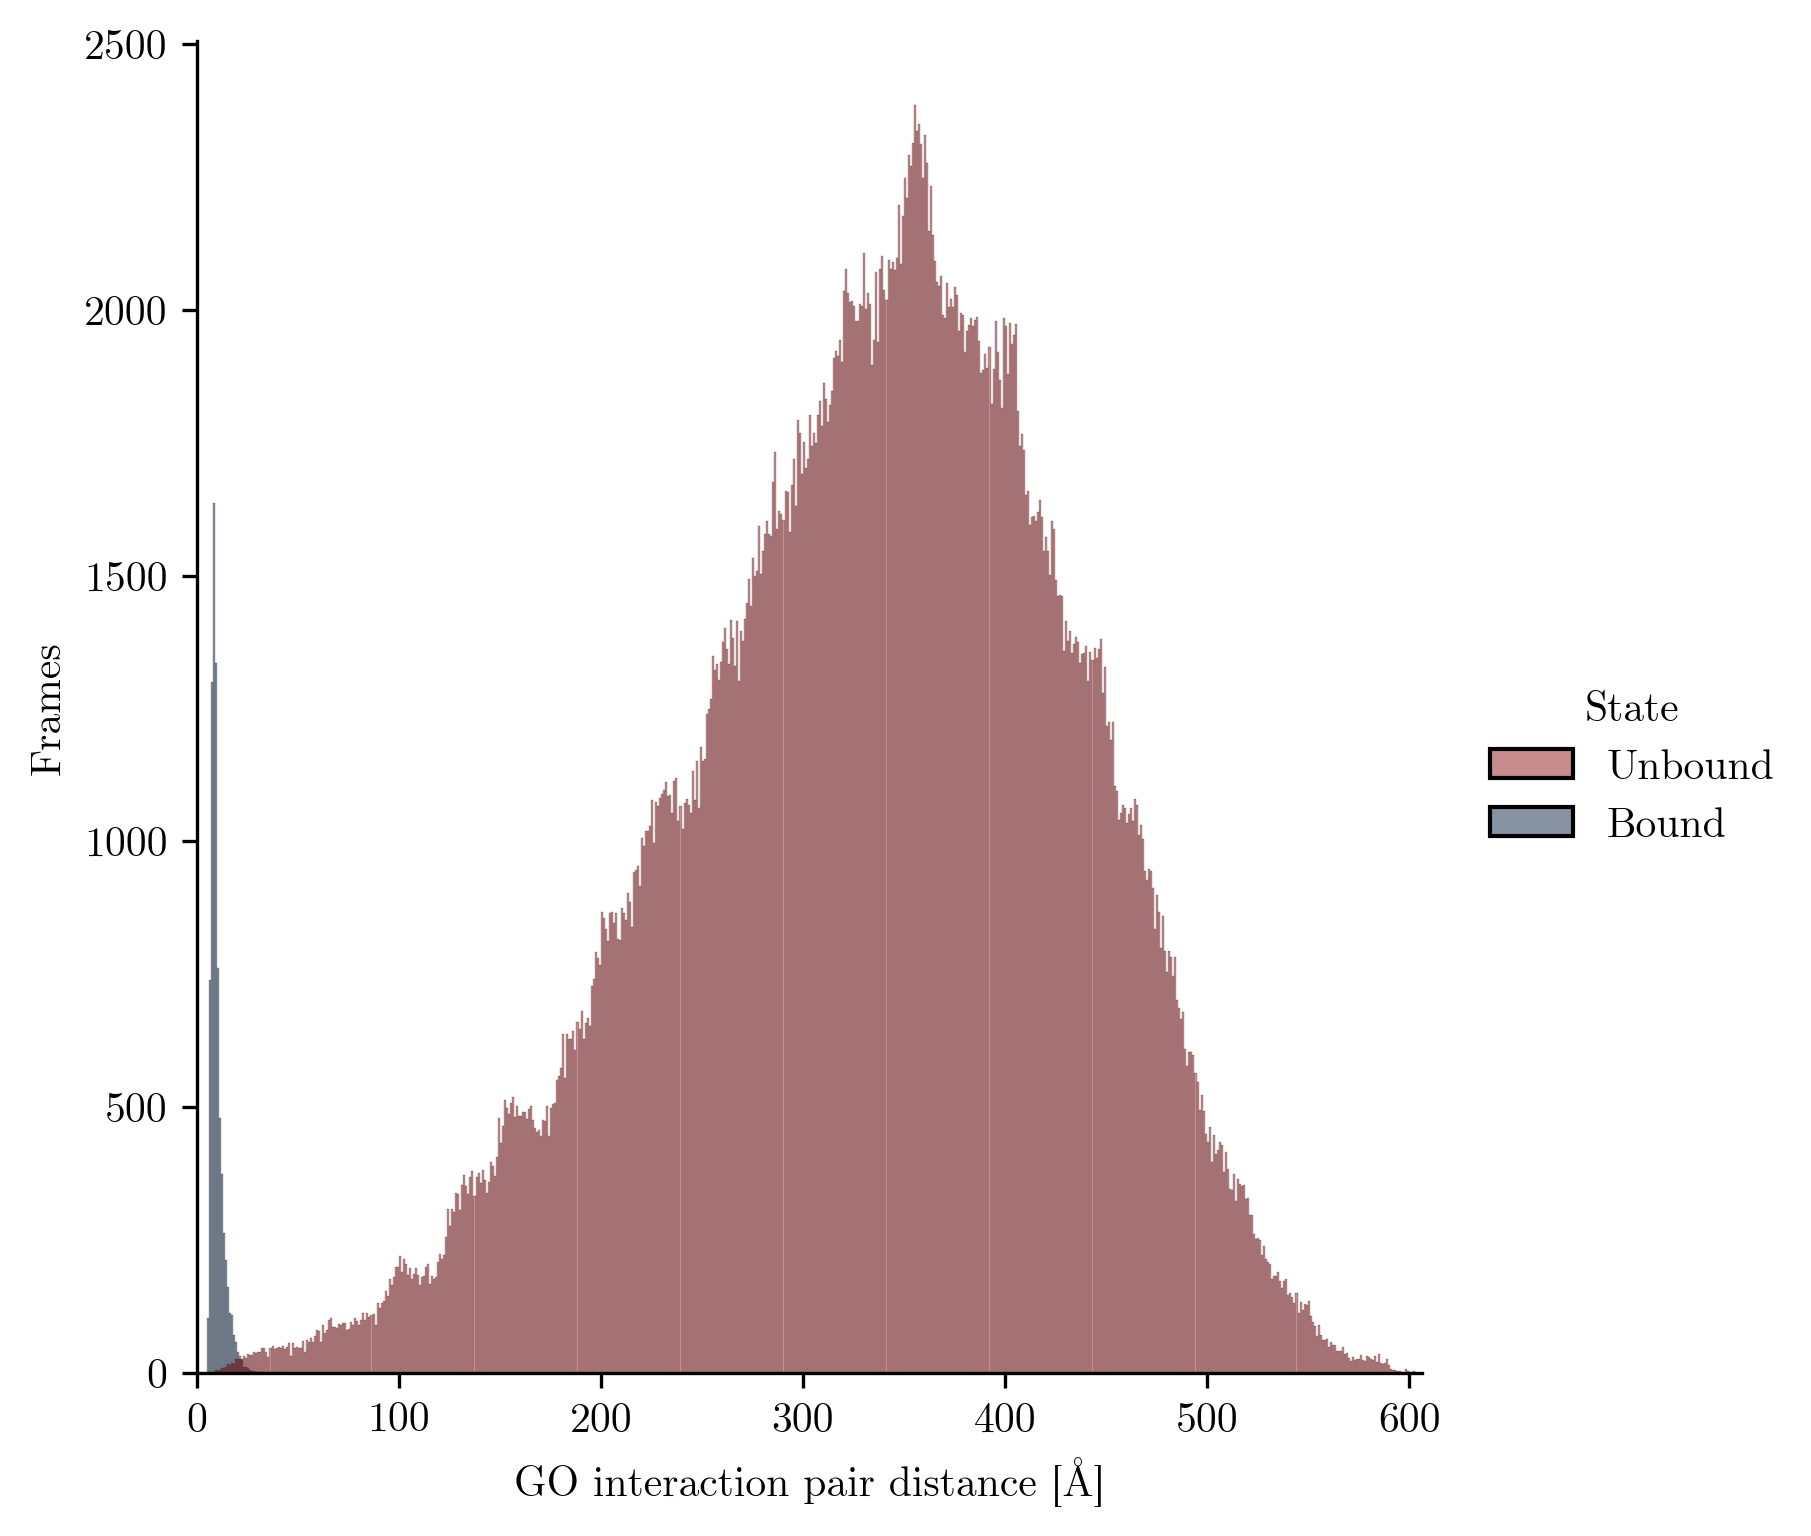

Text(25.074430555555498, 0.5, 'Frames')

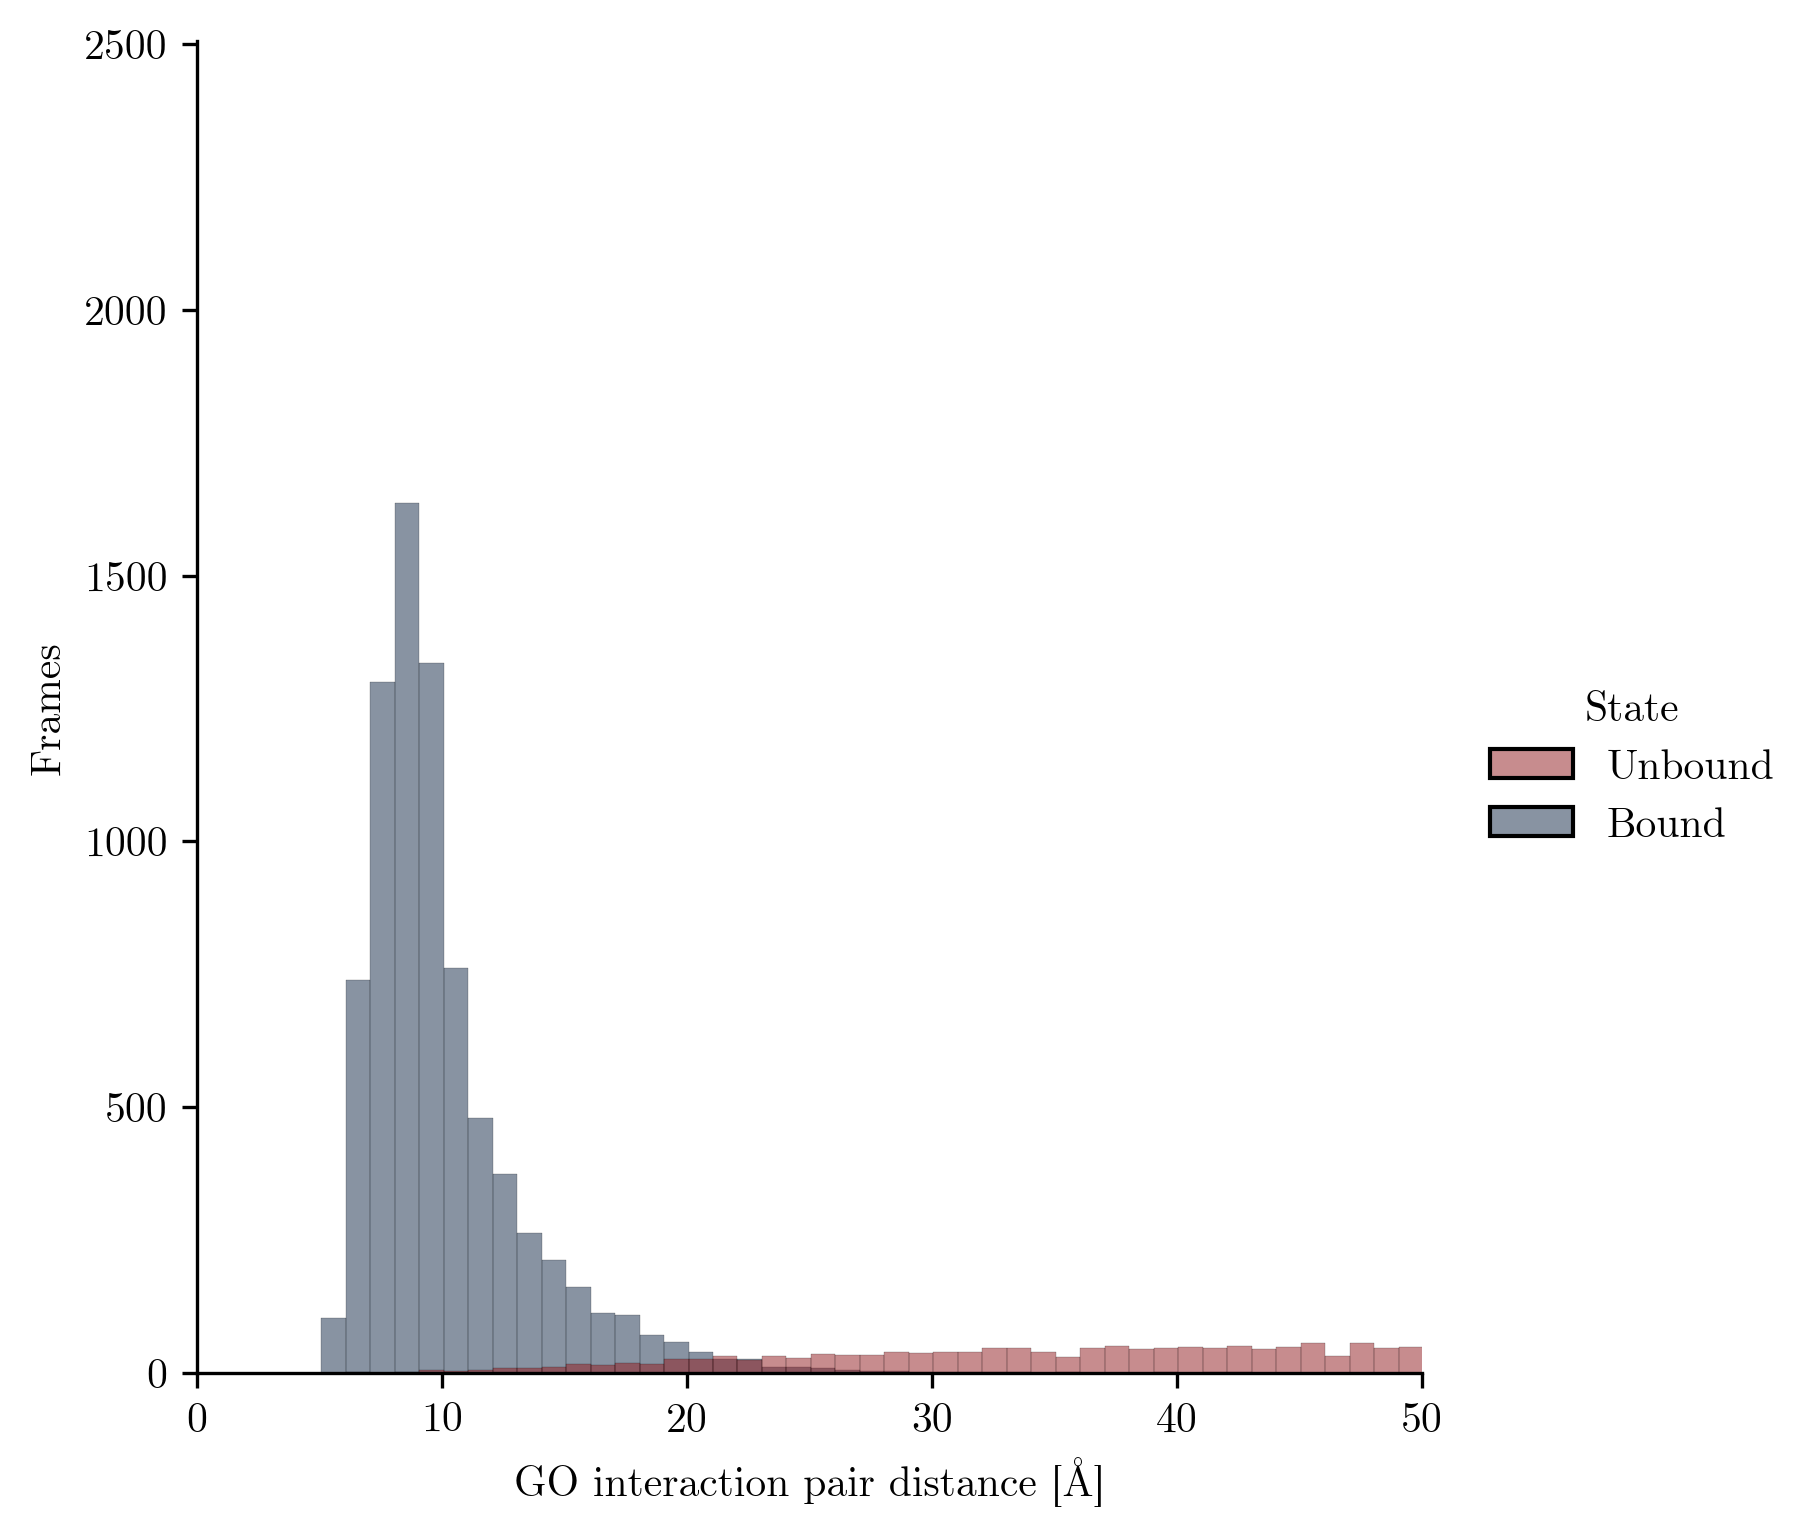

In [ ]:
# Distribution of interaction term distances
sns.displot(
    x=slim_dists.flatten(),
    binwidth=1,
    hue=pd.Series(np.repeat(bound_frames, slim_dists.shape[1]), name="State").map({True:'Bound', False:'Unbound'}),
)
plt.xlim(0,700*np.sqrt(3)/2)
plt.xlabel("GO interaction pair distance [Å]")
plt.ylabel("Frames")
plt.show()

sns.displot(
    x=slim_dists.flatten(),
    binwidth=1,
    hue=pd.Series(np.repeat(bound_frames, slim_dists.shape[1]), name="State").map({True:'Bound', False:'Unbound'}),
)
plt.xlim(0,50)
plt.xlabel("GO interaction pair distance [Å]")
plt.ylabel("Frames")

Text(0.5, 1.0, 'Convergence of 1-repeat PRM-SH3 $K_d$')

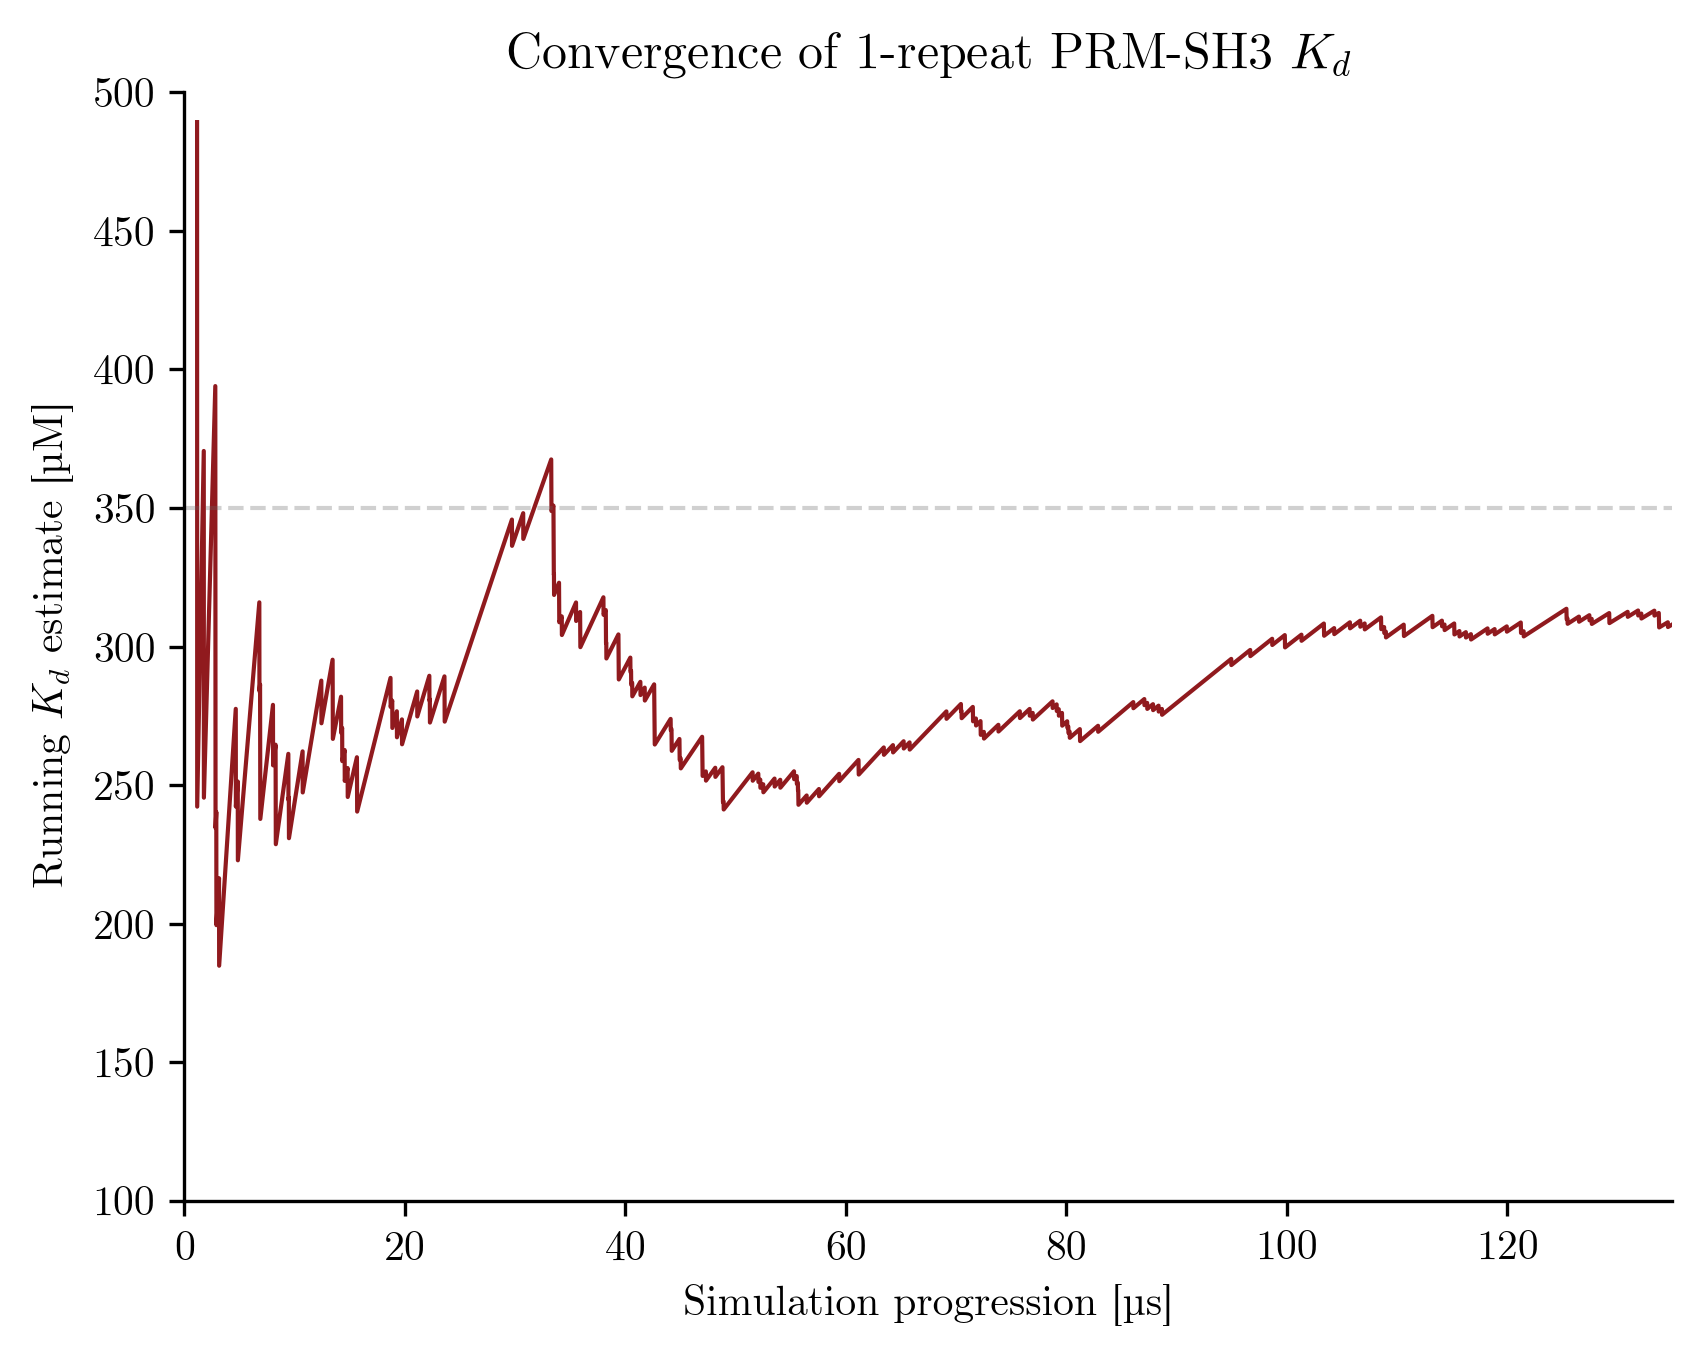

In [ ]:
# Convergence of Kd
fraction_bound_convergence = bound_frames.cumsum() / np.ones(bound_frames.shape[0]).cumsum()
Kd_convergence = calc_Kd(fraction_bound_convergence, chain_concentration)

plt.plot(time*1e-3, Kd_convergence, linewidth=1)
plt.xlim(0, total_time*1e-3)
plt.ylim(100,500)
plt.xlabel("Simulation progression [µs]")
plt.ylabel("Running $K_d$ estimate [µM]")
plt.hlines(350, *plt.xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1)
plt.title("Convergence of 1-repeat PRM-SH3 $K_d$")

Text(0.5, 1.0, 'Convergence of 1-repeat PRM-SH3 $K_d$')

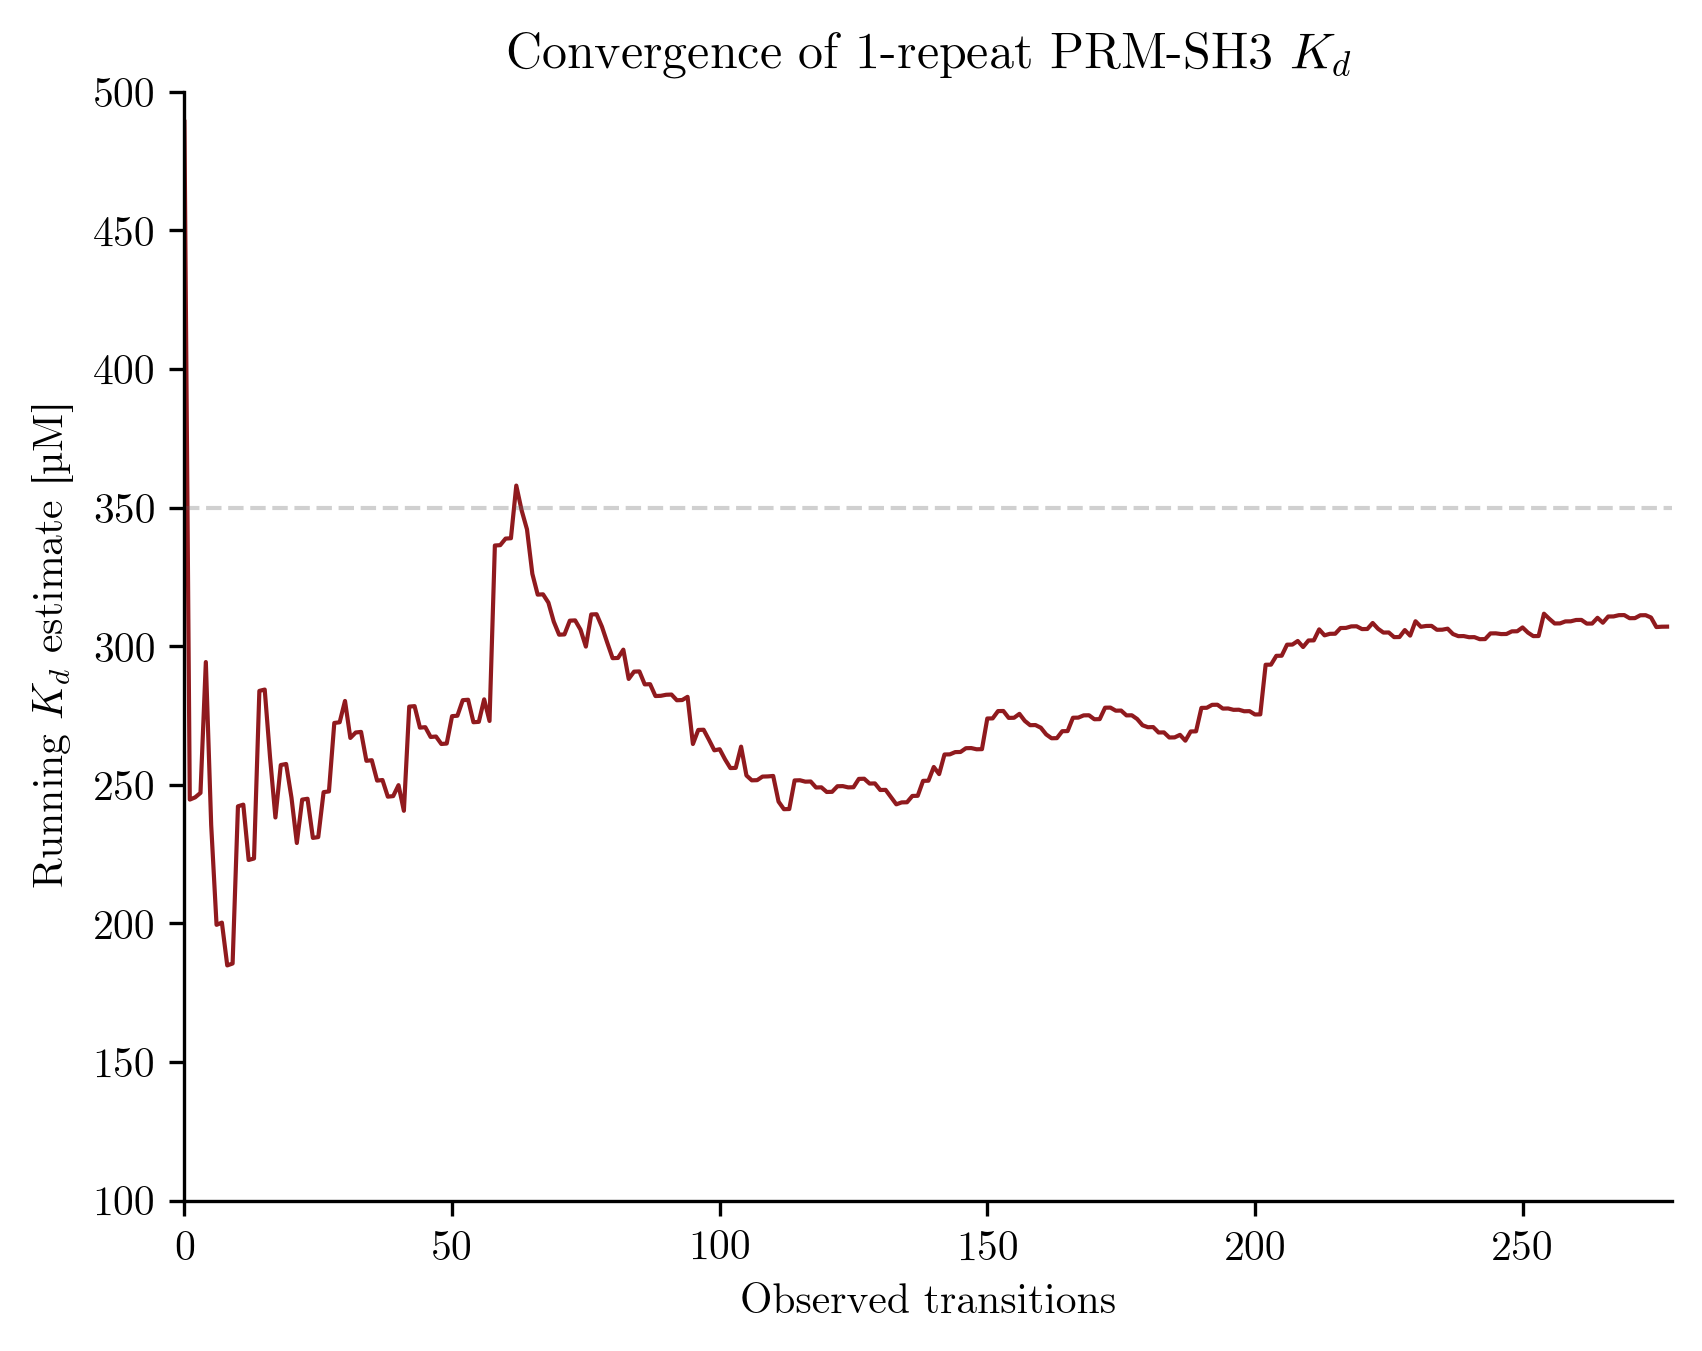

In [ ]:
plt.plot(Kd_convergence[1:][transitions])
plt.xlim(0,transitions.sum())
plt.ylim(100,500)
plt.xlabel("Observed transitions")
plt.ylabel("Running $K_d$ estimate [µM]")
plt.hlines(350, *plt.xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1)
plt.title("Convergence of 1-repeat PRM-SH3 $K_d$")

Text(0, 0.5, 'Observed transitions')

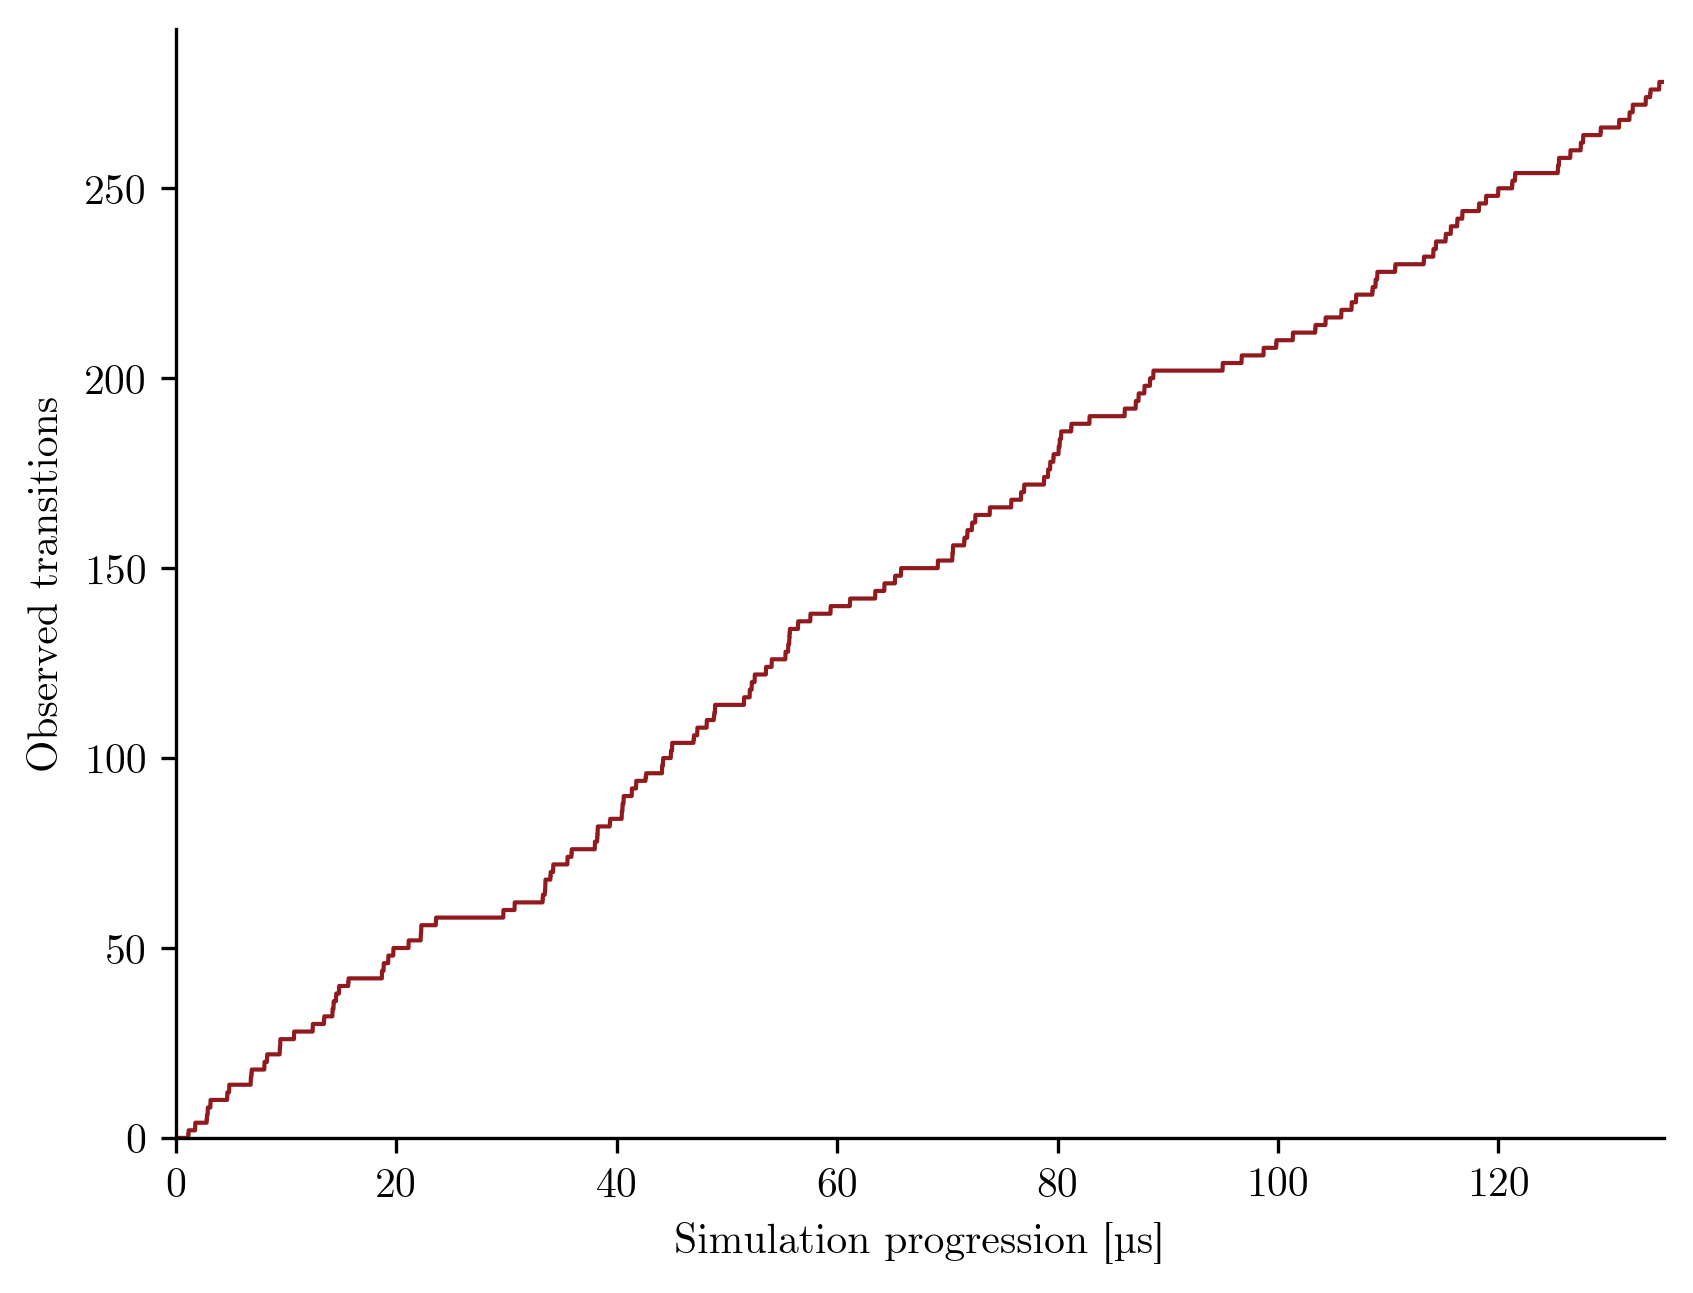

In [ ]:
plt.plot(time[1:]*1e-3, transitions.cumsum(), linewidth=1)
plt.xlim(0, total_time*1e-3)
plt.ylim(0)
plt.xlabel("Simulation progression [µs]")
plt.ylabel("Observed transitions")

(0.0, 1.0)

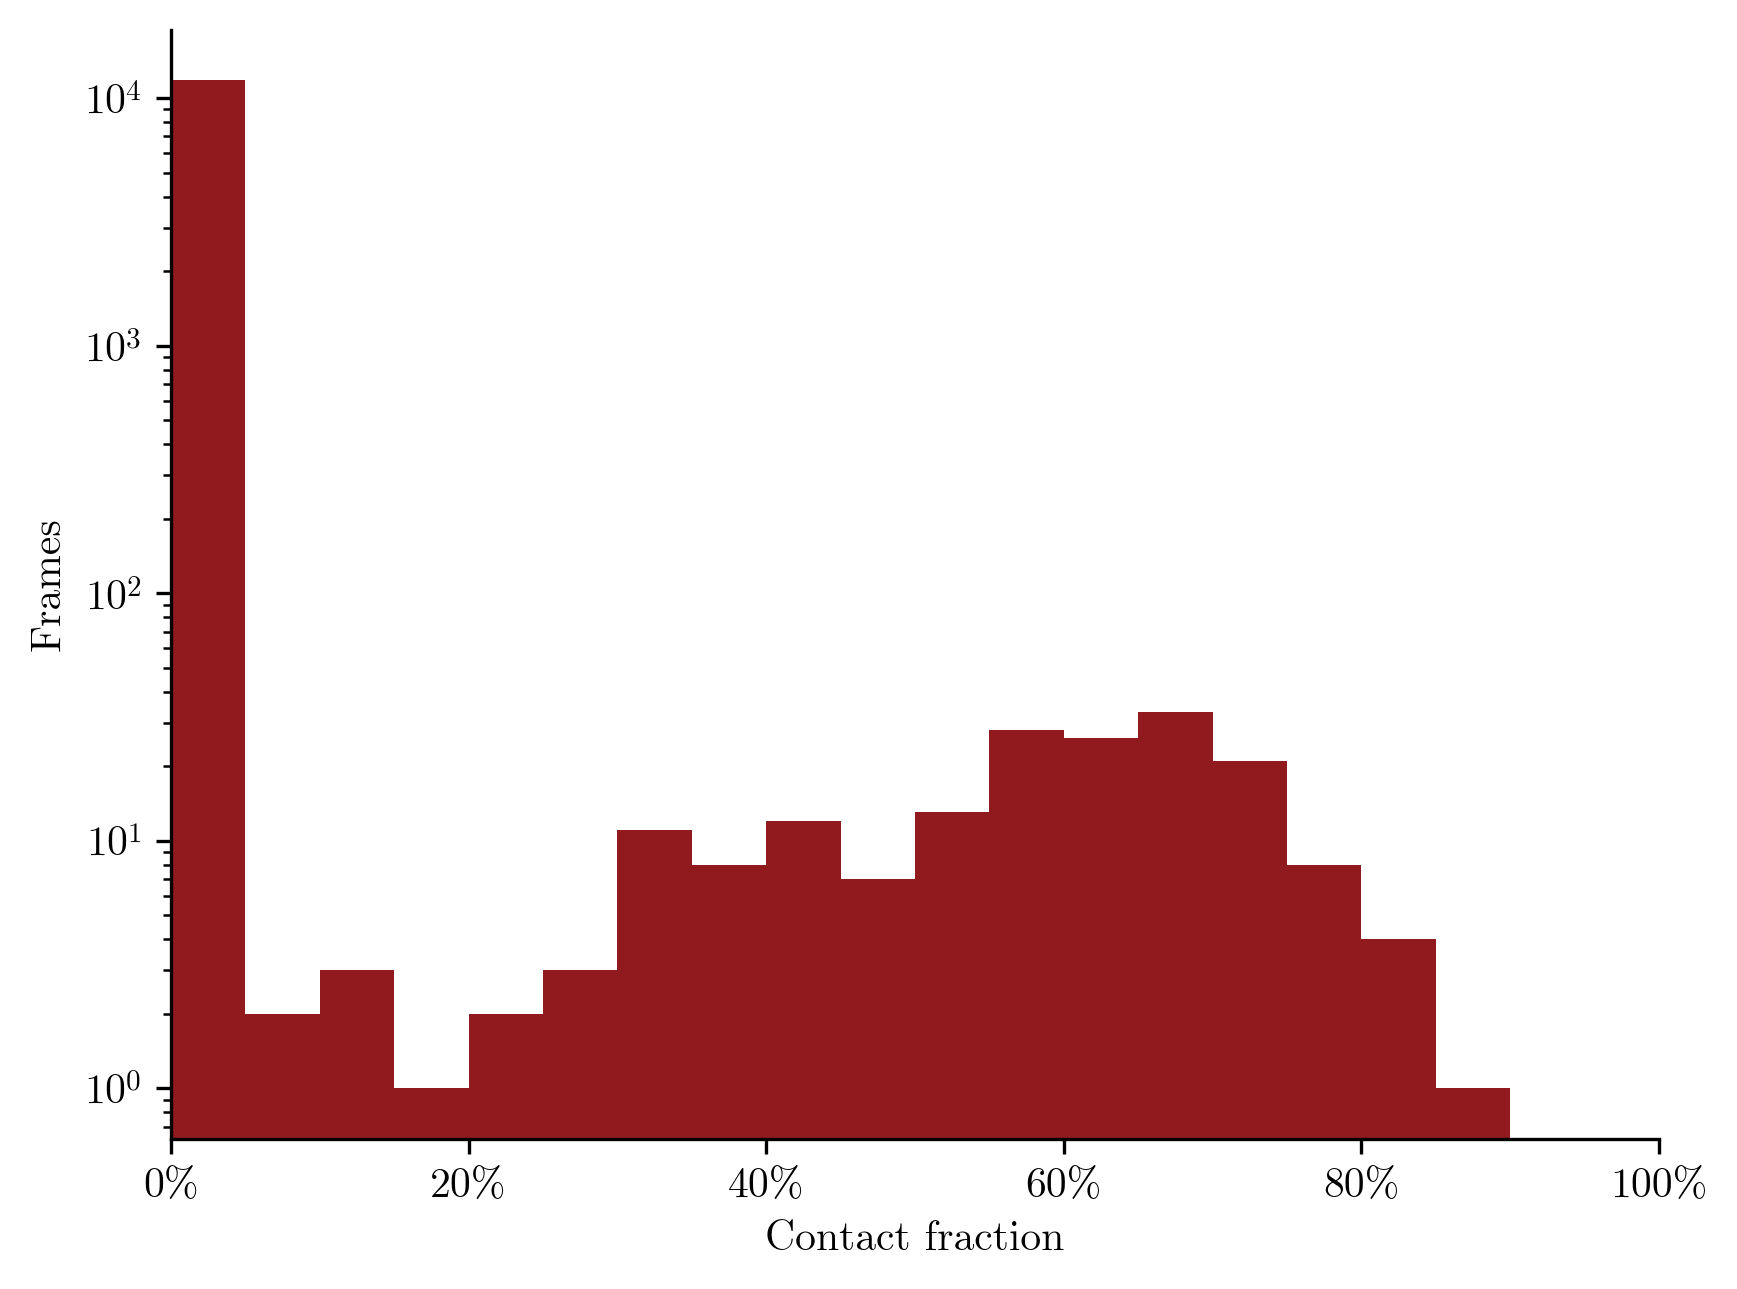

In [ ]:
plt.hist(slim_contacts.mean(axis=1), bins=np.arange(0,1,0.05))
plt.yscale('log')
vis.percent_axis('x')
plt.xlabel("Contact fraction")
plt.ylabel("Frames")
plt.xlim(0,1)

(0.0, 135.0)

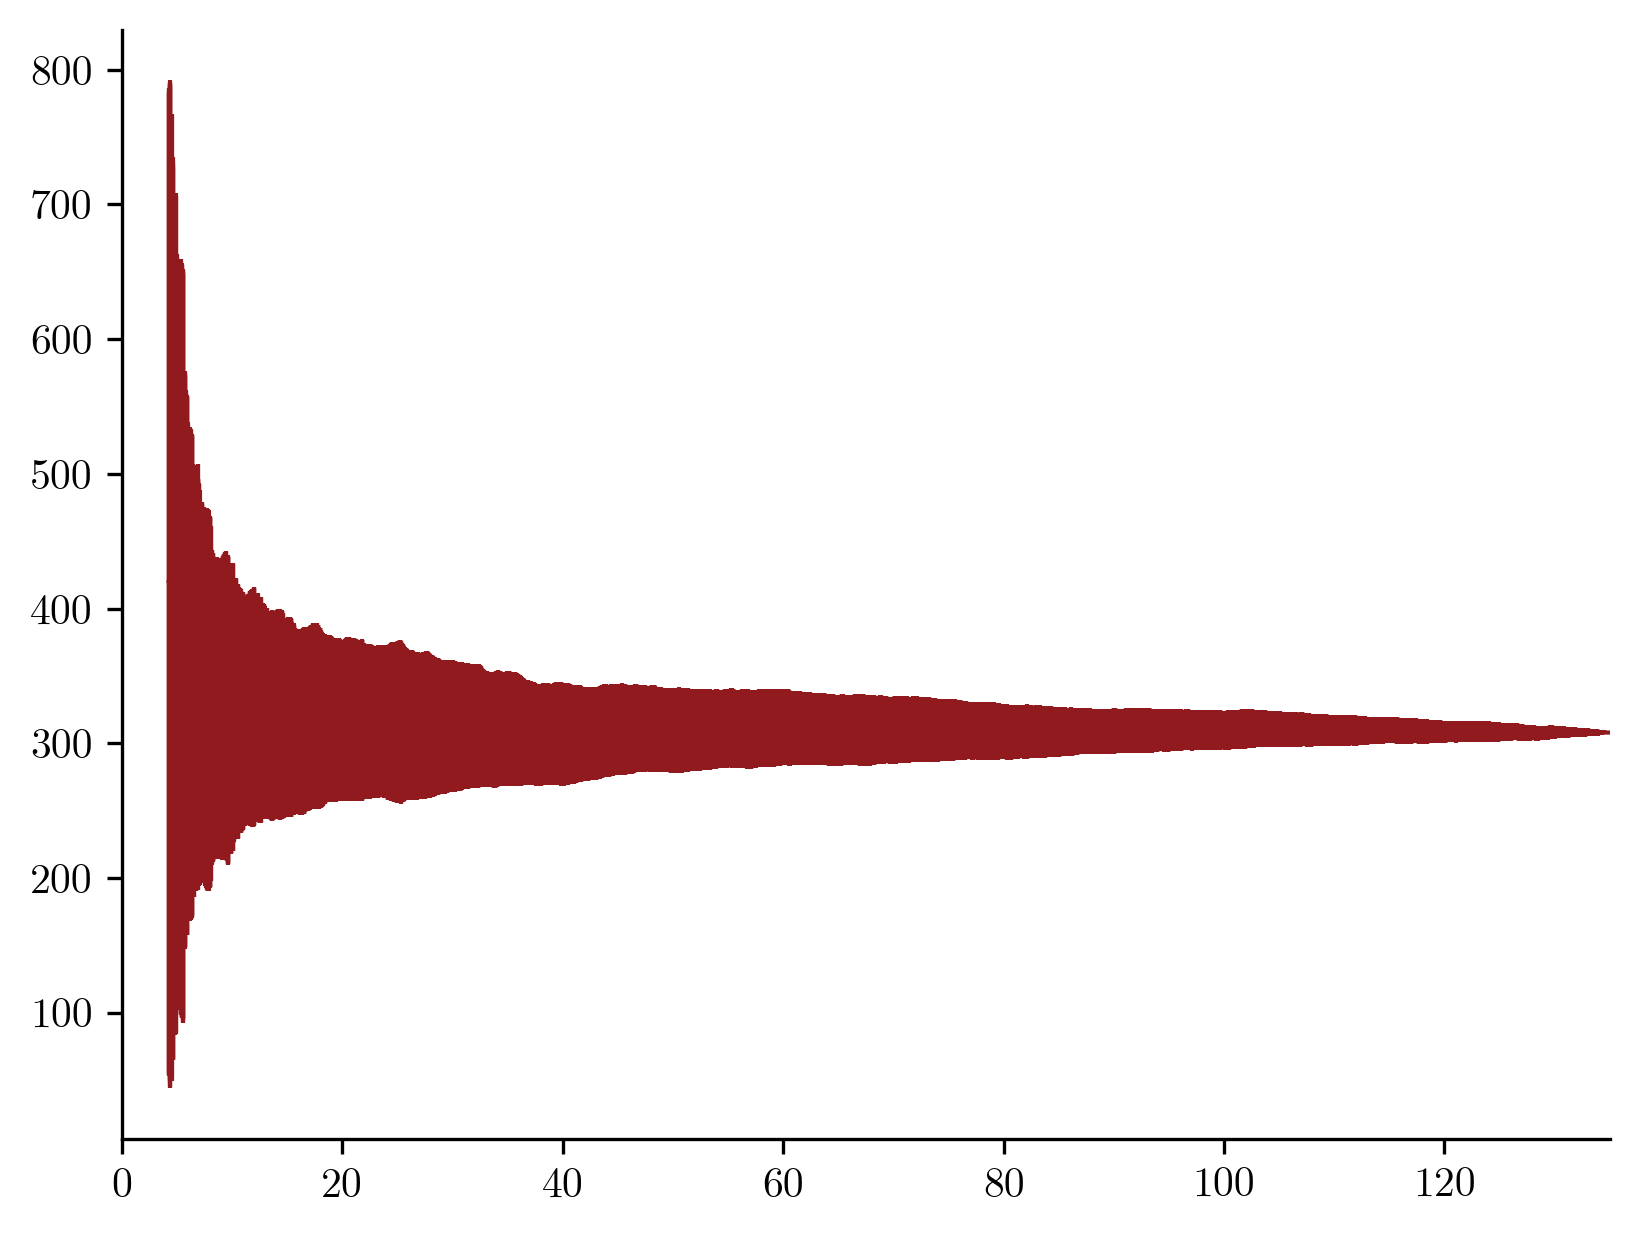

In [ ]:
# Convergence under shuffling
shuffles = 100
Kd_convergence_shuffleds = []
bound_frames_shuffled = bound_frames.copy()
for _ in range(shuffles):
    np.random.shuffle(bound_frames_shuffled)
    fraction_bound_convergence_shuffled = bound_frames_shuffled.cumsum() / np.ones(bound_frames_shuffled.shape[0]).cumsum()
    Kd_convergence_shuffled = calc_Kd(fraction_bound_convergence_shuffled, chain_concentration)
    Kd_convergence_shuffleds.append(Kd_convergence_shuffled)
Kd_convergence_shuffleds = np.array(Kd_convergence_shuffleds).T

plt.errorbar(
    time*1e-3,
    Kd_convergence_shuffleds.mean(axis=1),
    Kd_convergence_shuffleds.std(axis=1)
)
plt.xlim(0, total_time*1e-3)


## PRM-SH3 Single-chain single-repeat Parameter Scan

In [62]:
try:
    sims = pd.read_parquet('.temp/sims.parquet')


except FileNotFoundError:
    sim_dirs = [d for d in os.listdir('../data/prm_sh3_scan') if d[:6] == 'slabC3']

    sims = []
    for sim_dir in tqdm(sim_dirs):

        if sim_dir[:6] != 'slabC3':
            continue
        
        # Reading parameters
        epsilon = float(sim_dir.split('epsilon')[0].split('_')[-1])
        cutoff = float(sim_dir.split('GopairsCutoff')[-1].split('_')[0])
        
        # Loading trajectory
        dcd_path = f"../data/prm_sh3_scan/{sim_dir}/PRM1_SH31_1_1/traj_centered.dcd"
        pdb_path = f"../data/prm_sh3_scan/{sim_dir}/PRM1_SH31_1_1/traj_centered.pdb"
        traj = md.load(dcd_path, top=pdb_path)

        # Loading SLiM GO pairs
        slim_pair_indices = np.load(f'../data/prm_sh3_scan/{sim_dir}/PRM1_SH31_1_1/0/Go_pairs_list.npy')

        # Calculating concentration
        box_volume = traj.unitcell_volumes[0] * 1e-24 # L
        N_A = 6.02e23
        chains = 1
        chain_concentration = 1e6 * (chains) / (N_A * box_volume) # µM

        # Time
        n_frames = len(traj)
        dt = 5000 * 10e-6 # ns, stride x timestep
        total_time = n_frames * dt
        time = np.arange(0,total_time, step=dt)

        # SLiM contacts
        contact_cutoff = cutoff*10 # Å
        bound_cutoff = 0.05 # Fraction of contacts
        slim_dists = md.compute_distances(traj, slim_pair_indices, periodic=True) * 10.0 # Å
        slim_contacts = slim_dists <= contact_cutoff

        # Transitions
        bound_frames = slim_contacts.mean(axis=1) > bound_cutoff
        transitions = bound_frames[1:] != bound_frames[:-1]
        transitions = np.concatenate([[False],transitions])

        # Kd
        fc = bound_frames.mean()
        Kd = calc_Kd(fc, chain_concentration)

        # Kd convergence
        fc_convergence = bound_frames.cumsum() / np.ones(bound_frames.shape[0]).cumsum()
        Kd_convergence = calc_Kd(fc_convergence, chain_concentration)
        
        # Kd blocking
        fc_sem = calc_fc_sem_blocking(bound_frames)
        Kd_1sem = (float(calc_Kd(fc - 1*fc_sem, chain_concentration)), float(calc_Kd(fc + 1*fc_sem, chain_concentration)))
        Kd_2sem = (float(calc_Kd(fc - 2*fc_sem, chain_concentration)), float(calc_Kd(fc + 2*fc_sem, chain_concentration)))

        sims.append({
            'time': time,
            'epsilon': epsilon,
            'cutoff': cutoff,
            'Kd': float(Kd),
            'fc': fc,
            'fc_sem': fc_sem,
            'Kd_1sem': Kd_1sem,
            'Kd_2sem': Kd_2sem,
            'Kd_convergence': Kd_convergence,
            'transitions': transitions,
        })

    sims = pd.DataFrame(sims)
    sims.to_parquet('.temp/sims.parquet')

  4%|▍         | 1/25 [00:51<20:44, 51.87s/it]

Using block size of 1 frames...


  8%|▊         | 2/25 [02:30<30:25, 79.35s/it]

Using block size of 3125 frames...


 12%|█▏        | 3/25 [03:21<24:25, 66.63s/it]

Using block size of 160 frames...


... (40 outputs left out)

 96%|█████████▌| 24/25 [27:18<01:02, 62.68s/it]

Using block size of 1 frames...


100%|██████████| 25/25 [28:22<00:00, 68.10s/it]

Using block size of 24 frames...


Text(0.5, 0.98, 'Convergence of 1-repeat PRM-SH3 $K_d$')

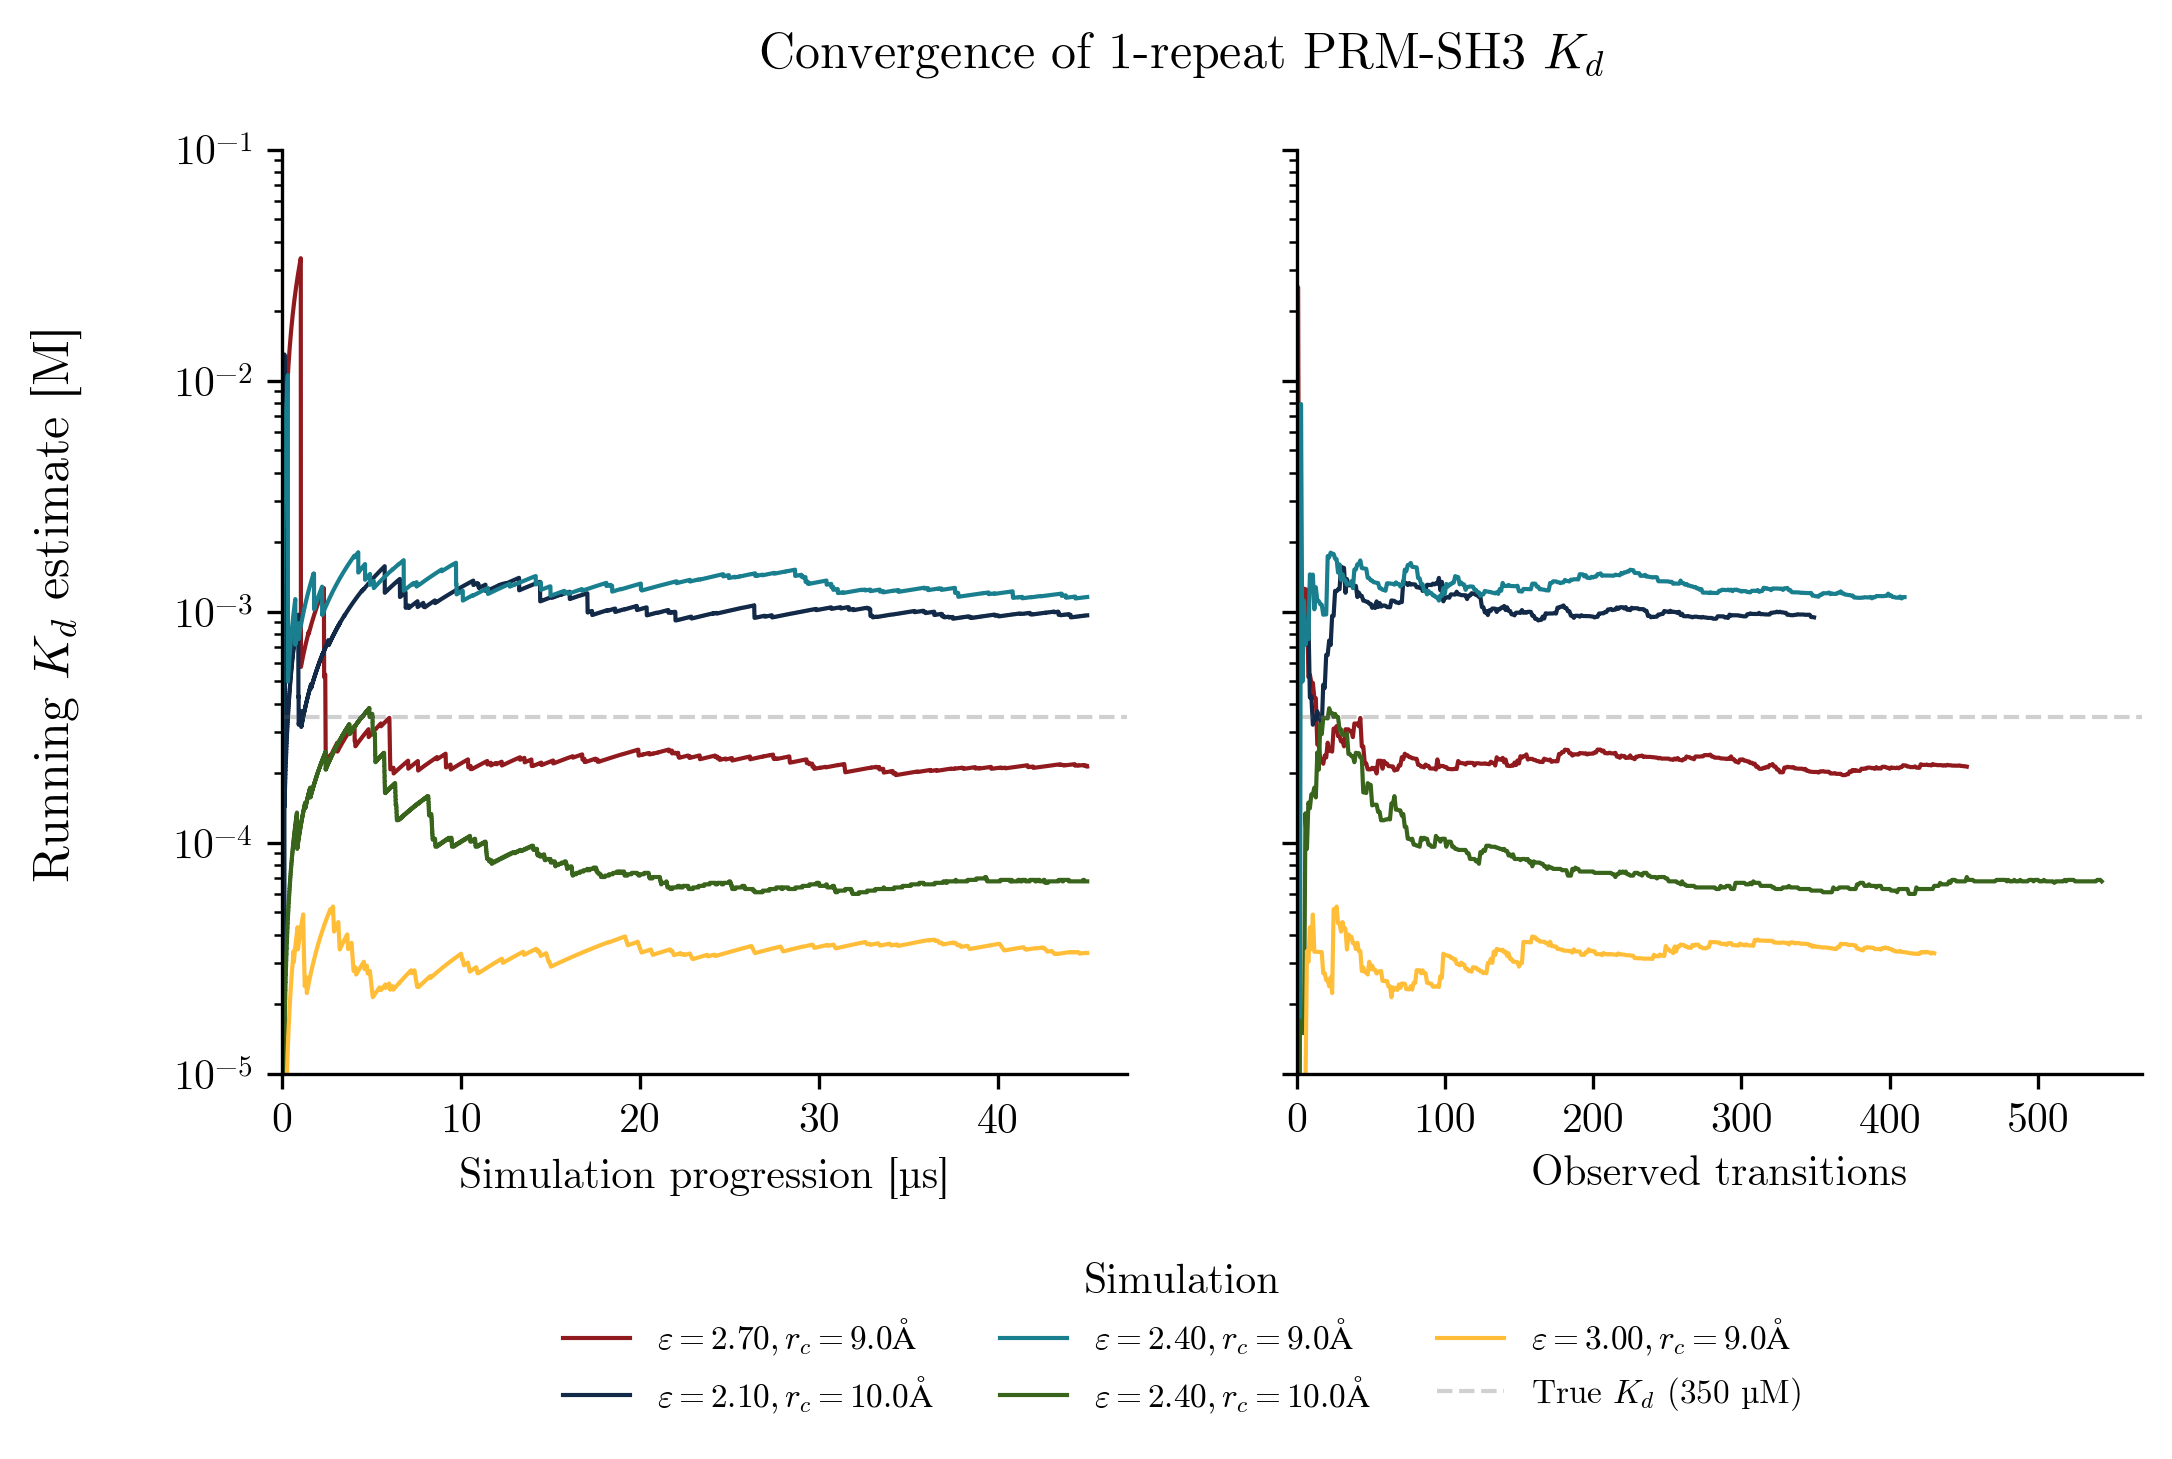

In [10]:
# Convergence between simulations
fig, axes = plt.subplots(1,2, sharey=True, figsize=(8,4))
true_Kd = 350
topn = 5

for sim_loc in (sims['Kd']/true_Kd).map(np.log10).abs().nsmallest(topn).index:
    sim = sims.loc[sim_loc]
    sim_label = r'$\varepsilon='+f'{sim["epsilon"]:.2f}' + r', r_c=' + f'{sim["cutoff"]*10:.1f}' +r'\text{Å}$'
    axes[0].plot(sim['time']*1e-3, sim['Kd_convergence']*1e-6, label=sim_label)
    axes[1].plot(sim['Kd_convergence'][sim['transitions']]*1e-6)

axes[0].set_xlim(0)
axes[0].set_yscale('log')
axes[0].set_ylim(1e-5,1e-1)
axes[0].hlines(true_Kd*1e-6, *axes[0].get_xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1,
               label=f"True $K_d$ ({true_Kd:.0f} µM)")
axes[0].set_xlabel("Simulation progression [µs]")

axes[1].set_xlim(0)
axes[1].hlines(true_Kd*1e-6, *axes[1].get_xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1)
axes[1].set_xlabel("Observed transitions")

fig.legend(loc='lower center', ncols=3, fontsize=8, frameon=False, alignment='center', title="Simulation",
           bbox_to_anchor=(0.5,-0.2))

fig.supylabel("Running $K_d$ estimate [M]")
fig.suptitle(f"Convergence of 1-repeat PRM-SH3 $K_d$")

/home/fknudsen/software/miniconda3/envs/calvados/lib/python3.10/site-packages/matplotlib/axes/_axes.py:3680: RuntimeWarning: invalid value encountered in add
  low, high = dep + np.vstack([-(1 - lolims), 1 - uplims]) * err


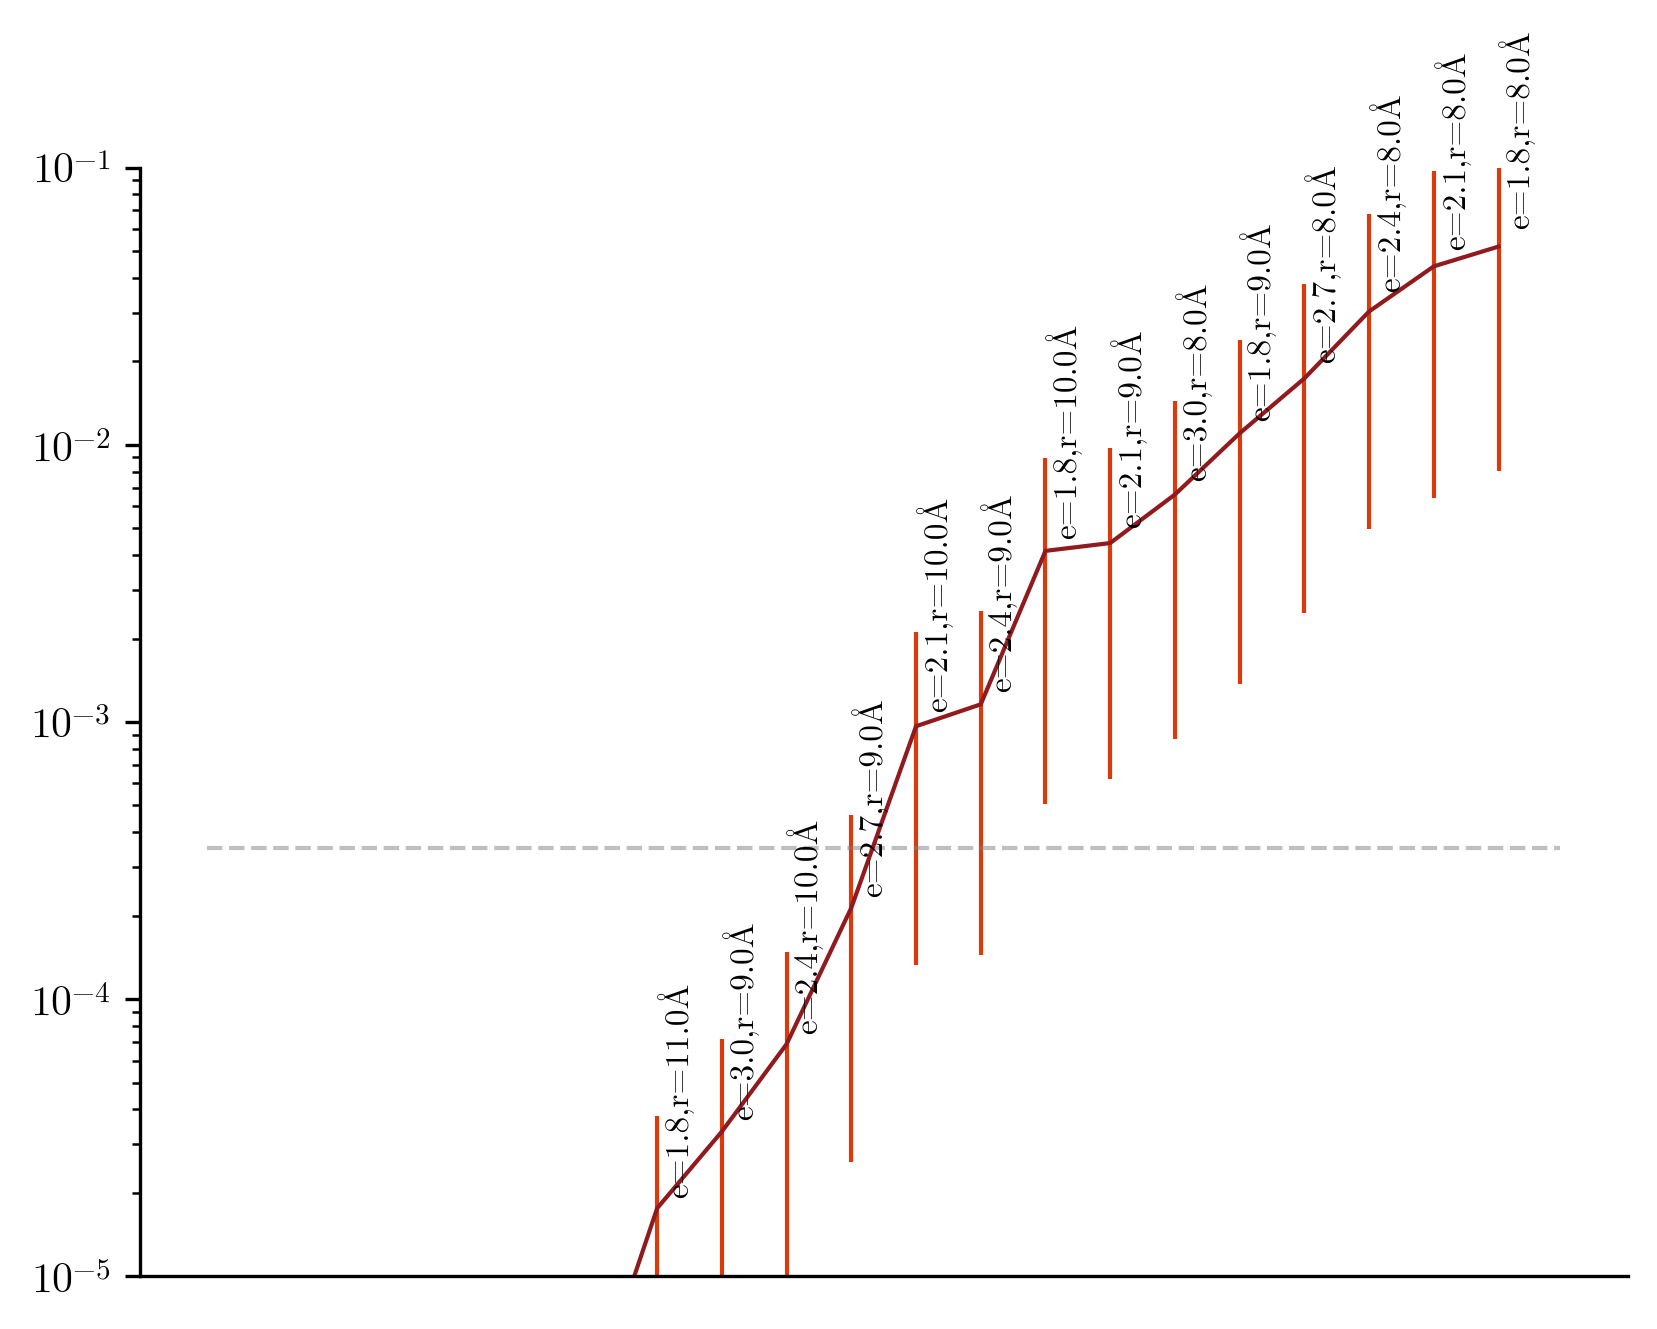

In [ ]:
# Blocking SEM estimates
Kd = sims['Kd'].sort_values()*1e-6
bounds = np.array(sims['Kd_1sem'].loc[Kd.index].map(list).to_list()).T[::-1]*1e-6
plt.errorbar(
    range(len(Kd)),
    Kd,
    bounds,
    ecolor=vis.light_red
)
plt.hlines(350e-6, *plt.xlim(), linestyle='dashed', color='grey', alpha=0.5)
plt.yscale('log')
plt.ylim(1e-5, 1e-1)
plt.xticks([])

for i, idx in enumerate(Kd.index):
    if bounds[1,i] == np.inf or bounds[1,i] < 1e-5:
        continue
    plt.text(i, bounds[1,i], f"e={sims['epsilon'].loc[idx]},r={sims['cutoff'].loc[idx]*10}Å", fontsize=8,rotation=90)

Text(156.88541666666669, 0.5, 'Go interaction strength $\\varepsilon$')

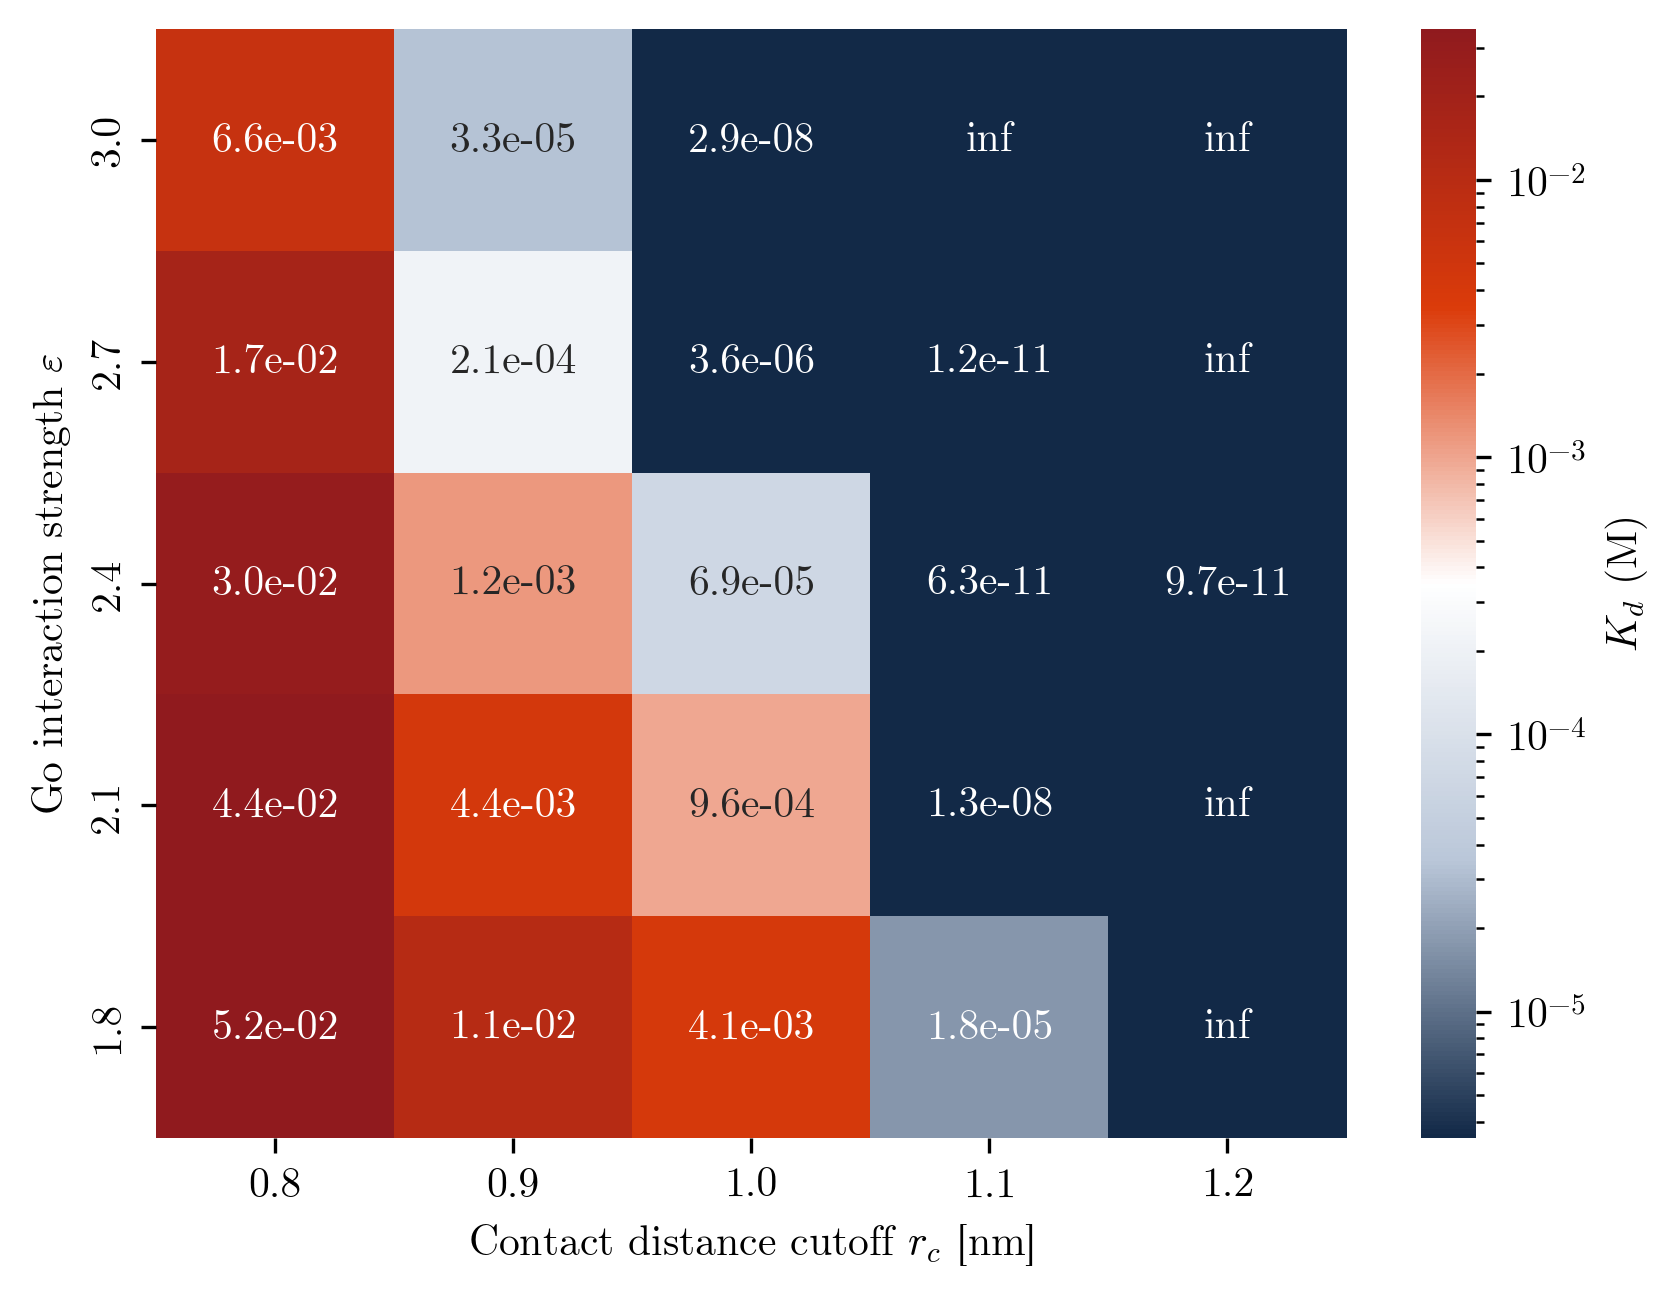

In [11]:
# Parameter landscape
import matplotlib.colors as colors

pivot_df = sims.sort_values(['epsilon', 'cutoff']).pivot(index='epsilon', columns='cutoff', values='Kd')[::-1] * 1e-6

midpoint = 350*1e-6
vmin = midpoint*1e-2
vmax = midpoint*1e2

norm = colors.LogNorm(vmin=vmin, vmax=vmax)

#plt.figure(figsize=(5, 5))
sns.heatmap(
    data=pivot_df.replace({np.inf: 1e-15}),
    norm=norm,
    cmap=vis.cmap.heat_cmap, 
    #center=midpoint, 
    annot=pivot_df,
    fmt=".1e",
    cbar_kws={'label': '$K_d$ (M)'}
)
plt.xlabel(r"Contact distance cutoff $r_c$ [nm]")
plt.ylabel(r"Go interaction strength $\varepsilon$")

Text(0, 0.5, 'Observed transitions')

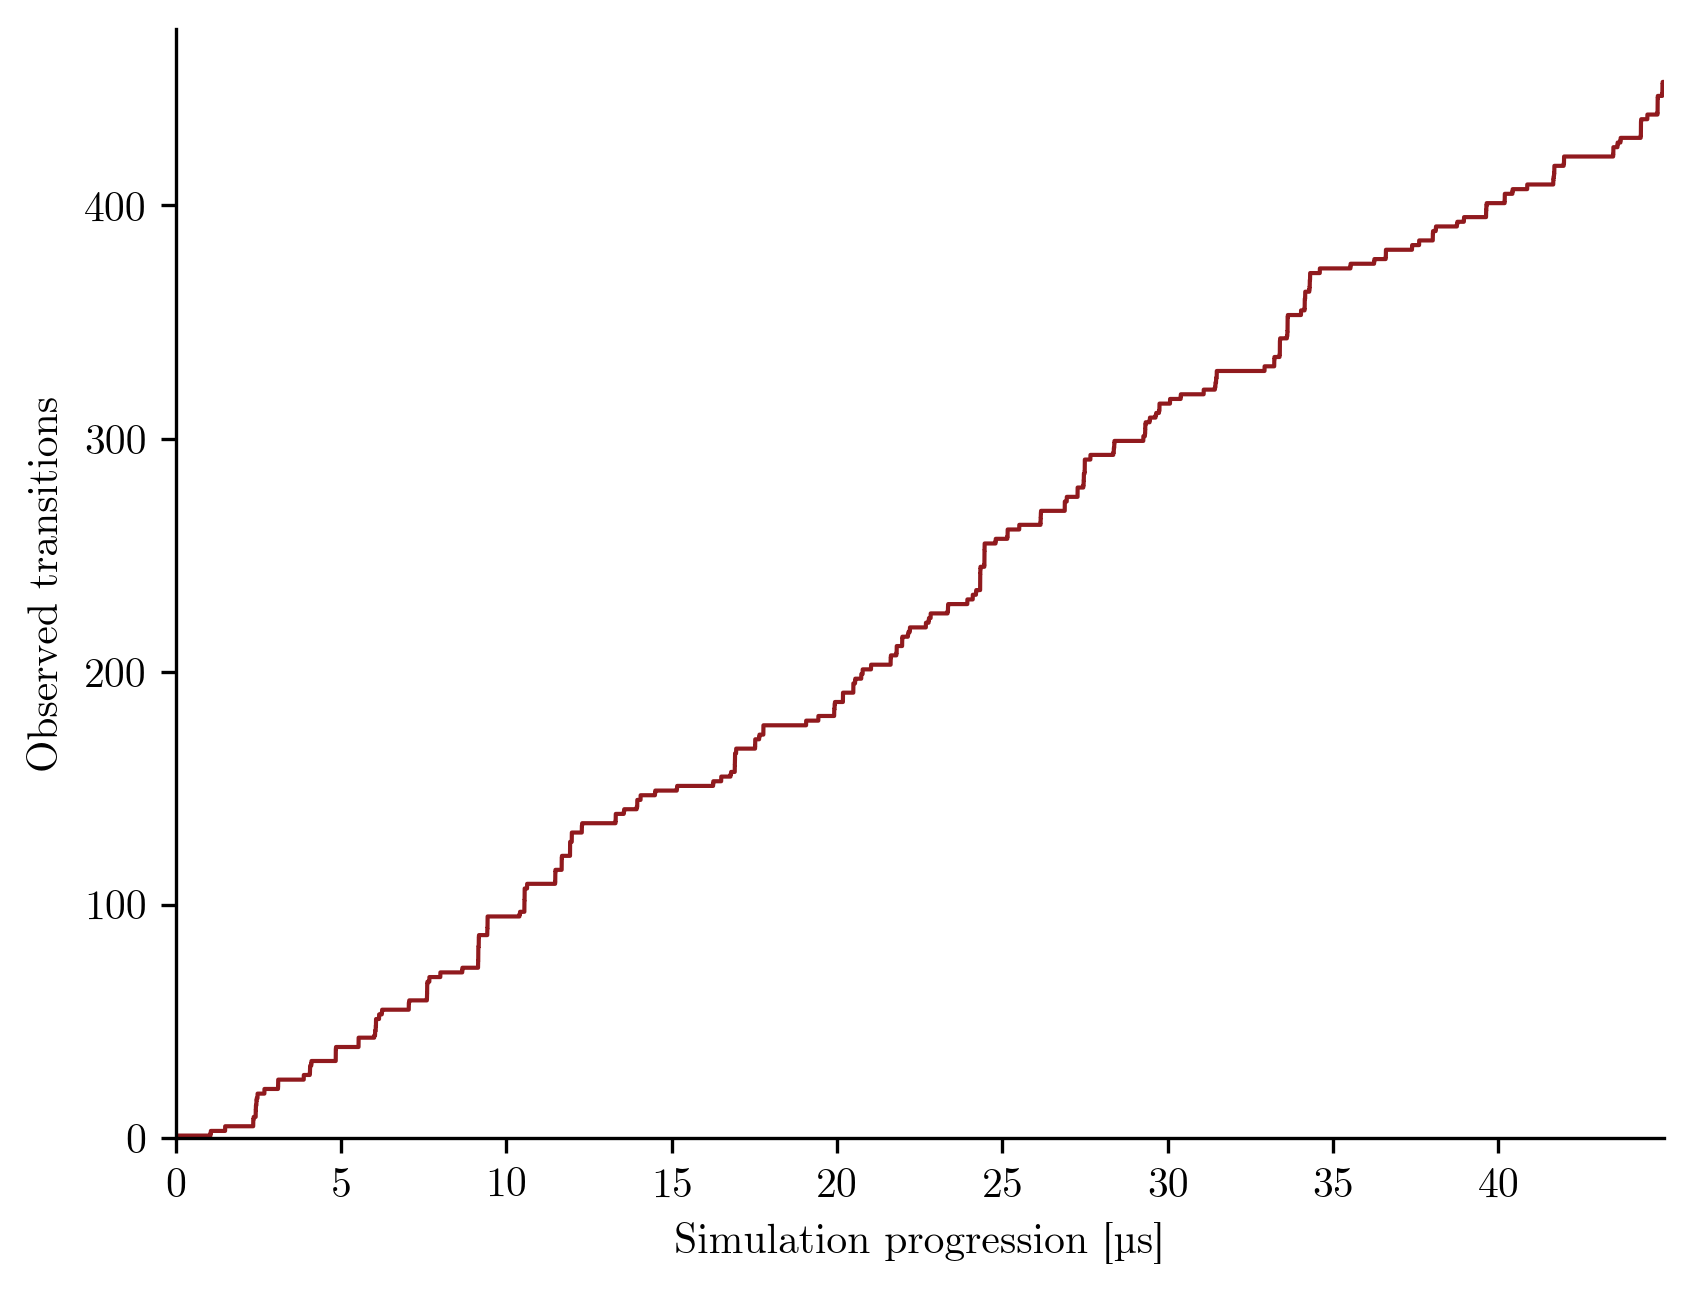

In [144]:
sim = sims.loc[20]
plt.plot(sim['time']*1e-3, sim['transitions'].cumsum(), linewidth=1)
plt.xlim(0, sim['time'][-1]*1e-3)
plt.ylim(0)
plt.xlabel("Simulation progression [µs]")
plt.ylabel("Observed transitions")